In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("used_cars_data.csv")

print("="*60)
print("Dataset Shape:",df.shape)

print("\nFirst Five Rows")
print(df.head())

print("\nDataset Information")
print(df.info())

print("\nStatistical Summary")
print(df.describe(include='all'))

Dataset Shape: (7253, 14)

First Five Rows
   S.No.                              Name    Location  Year  \
0      0            Maruti Wagon R LXI CNG      Mumbai  2010   
1      1  Hyundai Creta 1.6 CRDi SX Option        Pune  2015   
2      2                      Honda Jazz V     Chennai  2011   
3      3                 Maruti Ertiga VDI     Chennai  2012   
4      4   Audi A4 New 2.0 TDI Multitronic  Coimbatore  2013   

   Kilometers_Driven Fuel_Type Transmission Owner_Type     Mileage   Engine  \
0              72000       CNG       Manual      First  26.6 km/kg   998 CC   
1              41000    Diesel       Manual      First  19.67 kmpl  1582 CC   
2              46000    Petrol       Manual      First   18.2 kmpl  1199 CC   
3              87000    Diesel       Manual      First  20.77 kmpl  1248 CC   
4              40670    Diesel    Automatic     Second   15.2 kmpl  1968 CC   

       Power  Seats  New_Price  Price  
0  58.16 bhp    5.0        NaN   1.75  
1  126.2 bhp    5

In [3]:
print("\nMissing Values")
missing=pd.DataFrame({"Missing":df.isnull().sum(),
                      "Percentage":round(df.isnull().mean()*100,2)
                     })
missing=missing[missing["Missing"]>0]
print(missing.sort_values("Percentage",ascending=False))


Missing Values
           Missing  Percentage
New_Price     6247       86.13
Price         1234       17.01
Seats           53        0.73
Engine          46        0.63
Power           46        0.63
Mileage          2        0.03


In [4]:
print("\nDuplicate Rows:",df.duplicated().sum())


Duplicate Rows: 0


In [5]:
print("\nData Types")
print(df.dtypes)


Data Types
S.No.                  int64
Name                  object
Location              object
Year                   int64
Kilometers_Driven      int64
Fuel_Type             object
Transmission          object
Owner_Type            object
Mileage               object
Engine                object
Power                 object
Seats                float64
New_Price             object
Price                float64
dtype: object


In [9]:
if "S.No." in df.columns:
    df.drop("S.No.",axis=1,inplace=True)

In [10]:
df["Brand"]=df["Name"].str.split().str[0]

In [11]:
df["Mileage"]=(
    df["Mileage"]
        .astype(str)
        .str.extract(r'([\d.]+)')
        .astype(float)
)

In [12]:
df["Engine"]=(
    df["Engine"].astype(str).str.extract(r'([\d.]+)').astype(float)
)

In [13]:
df["Power"]=(
    df["Power"].astype(str).str.extract(r'([\d.]+)').astype(float)
)

In [14]:
df["New_Price"]=(
    df["New_Price"].astype(str).str.extract(r'([\d.]+)').astype(float)
)

In [15]:
num_cols=df.select_dtypes(include=np.number).columns
cat_cols=df.select_dtypes(exclude=np.number).columns

for col in num_cols:
    df[col].fillna(df[col].median(),inplace=True)

for col in cat_cols:
    df[col].fillna(df[col].mode()[0],inplace=True)

C:\Users\syedr\AppData\Local\Temp\ipykernel_13528\4035490192.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(),inplace=True)
C:\Users\syedr\AppData\Local\Temp\ipykernel_13528\4035490192.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For exampl

In [16]:
CURRENT_YEAR=2024

df["Car_Age"]=CURRENT_YEAR-df["Year"]

df["Price_per_KM"]=(df["Price"]/(df["Kilometers_Driven"]+1))

df["Power_per_Engine"]=(df["Power"]/df["Engine"])

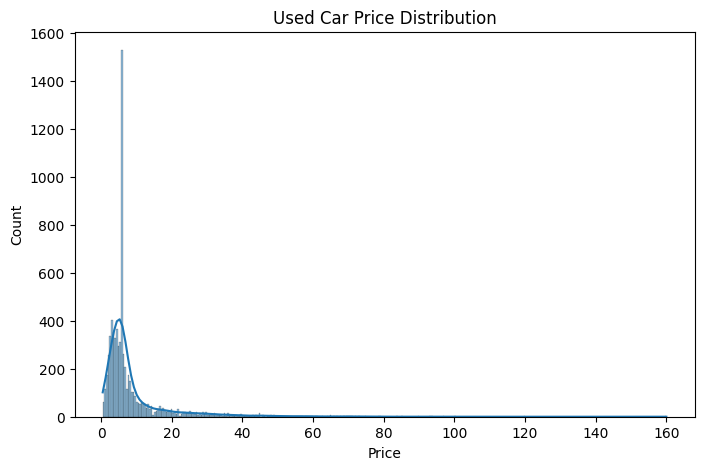

In [17]:
plt.figure(figsize=(8,5))
sns.histplot(df["Price"],kde=True)

plt.title("Used Car Price Distribution")
plt.show()

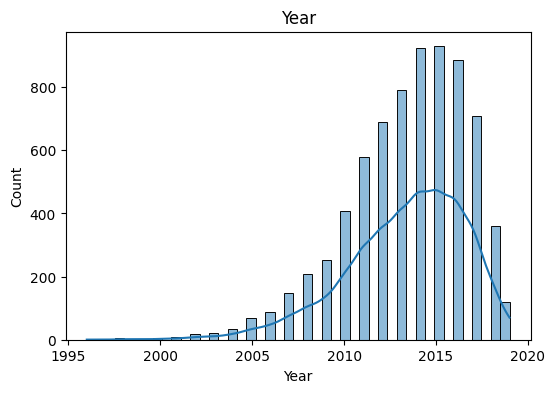

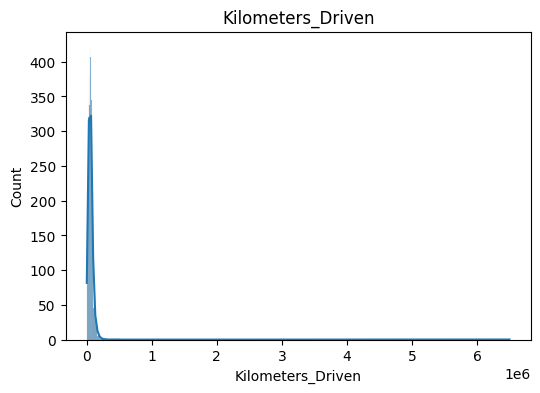

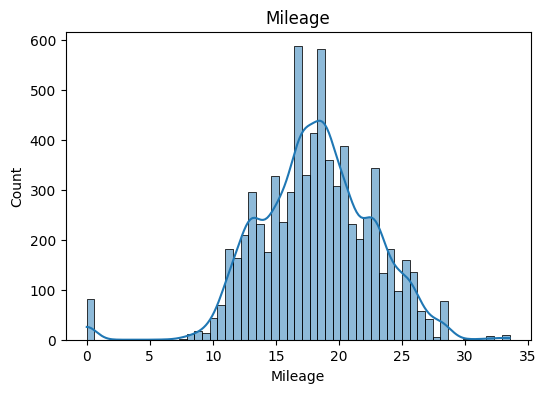

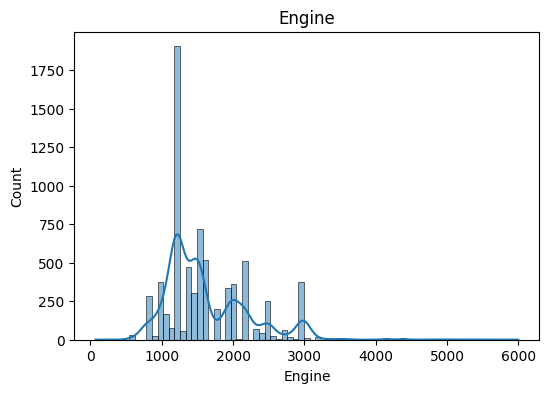

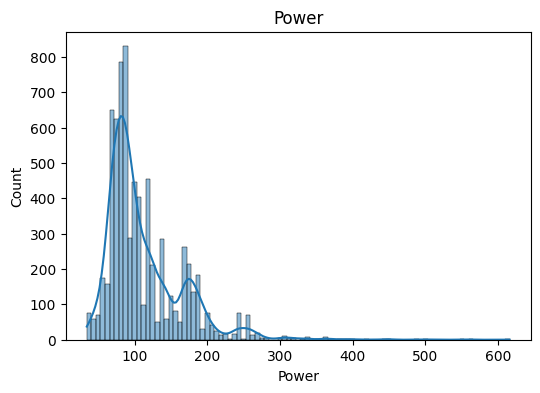

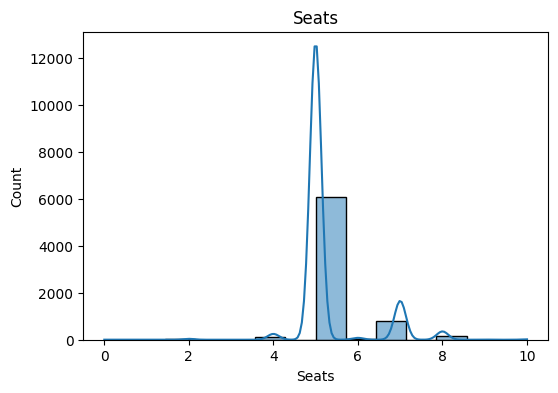

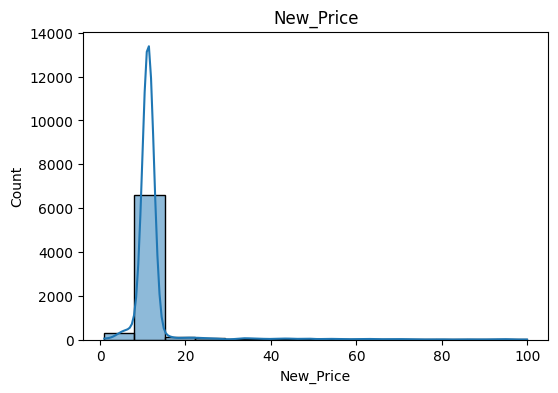

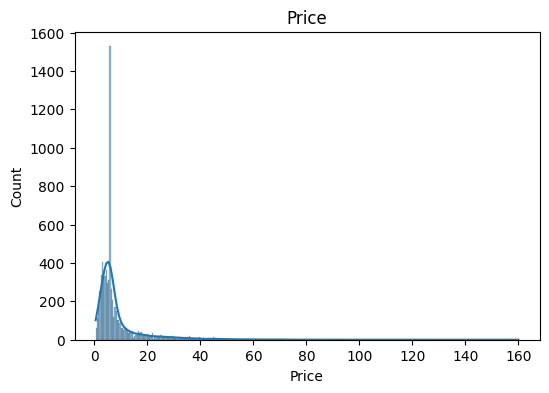

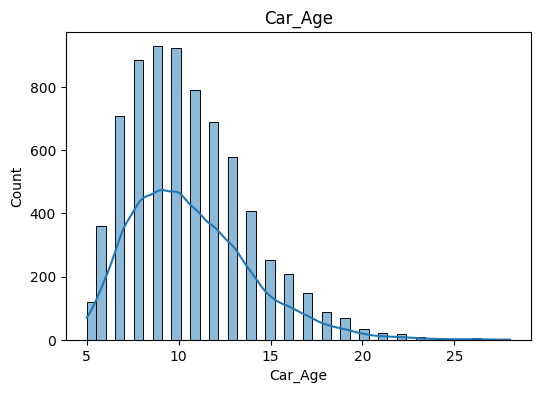

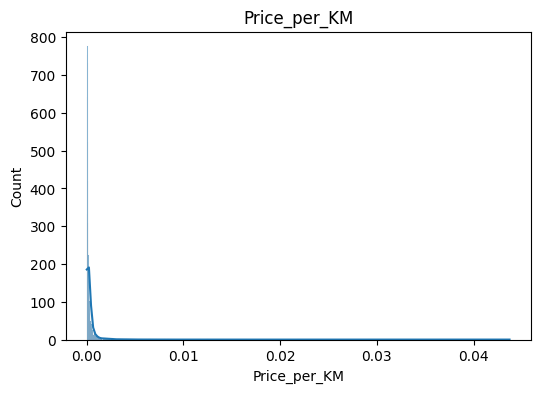

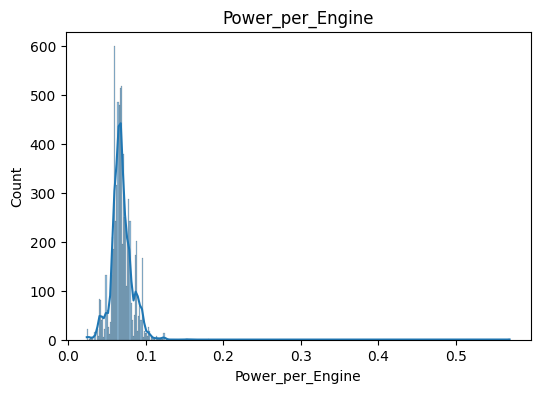

In [18]:
numerical=df.select_dtypes(include=np.number)

for col in numerical.columns:
    plt.figure(figsize=(6,4))
    sns.histplot(df[col],kde=True)
    plt.title(col)
    plt.show()

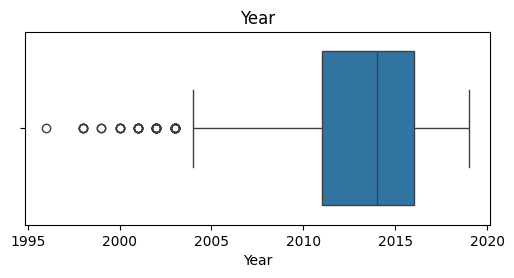

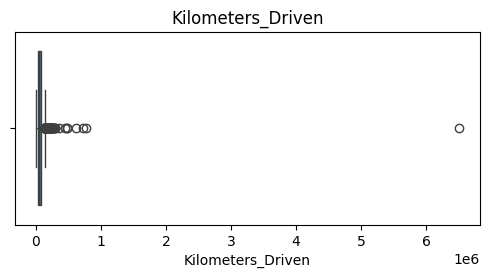

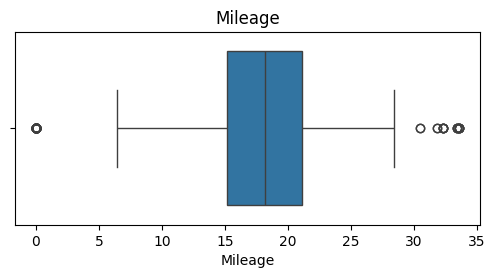

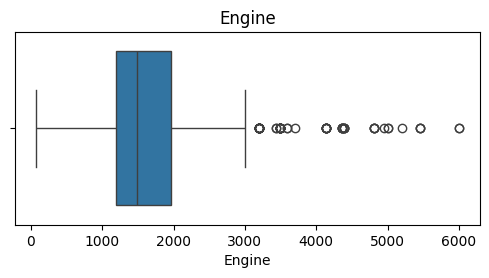

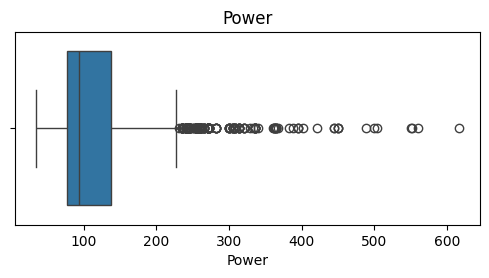

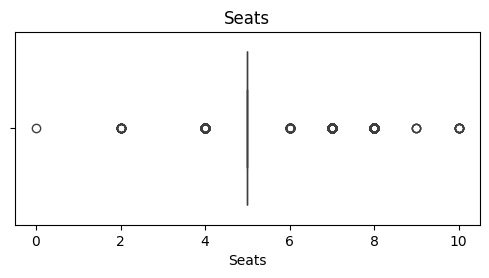

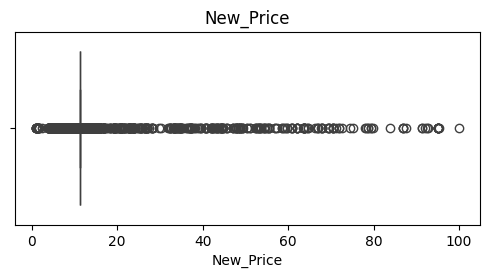

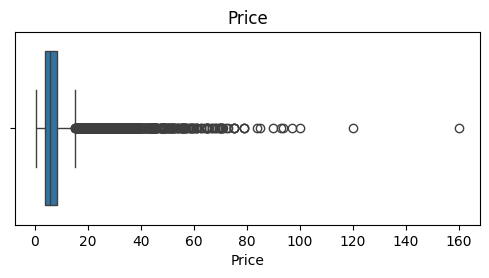

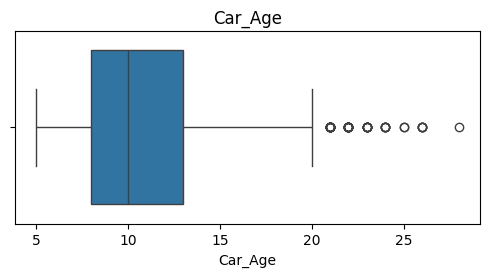

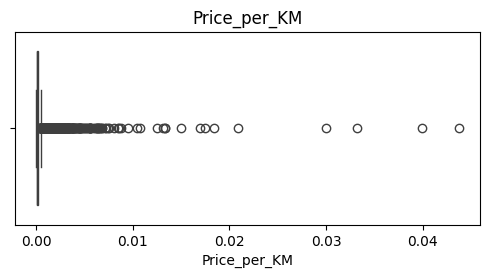

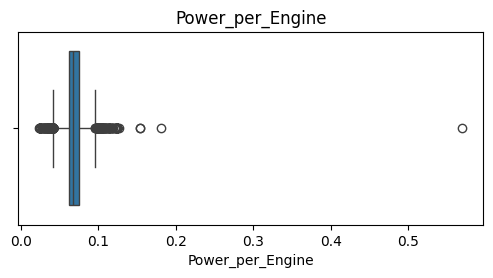

In [19]:
for col in numerical.columns:
    plt.figure(figsize=(6,2.5))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

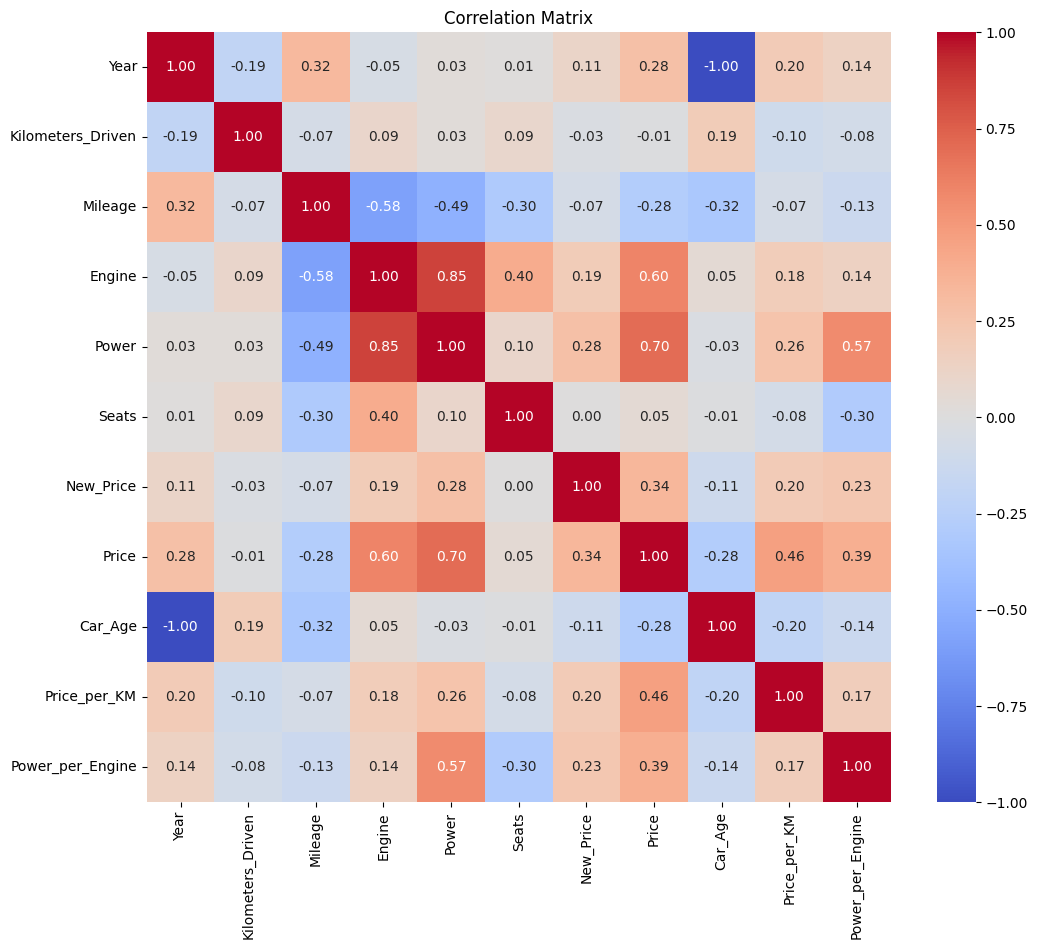

In [20]:
plt.figure(figsize=(12,10))

corr=numerical.corr()

sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [21]:
print("\nCorrelation With Price")
print(corr["Price"].sort_values(ascending=False))


Correlation With Price
Price                1.000000
Power                0.702492
Engine               0.601519
Price_per_KM         0.463109
Power_per_Engine     0.385774
New_Price            0.339422
Year                 0.276009
Seats                0.047136
Kilometers_Driven   -0.011062
Car_Age             -0.276009
Mileage             -0.278190
Name: Price, dtype: float64


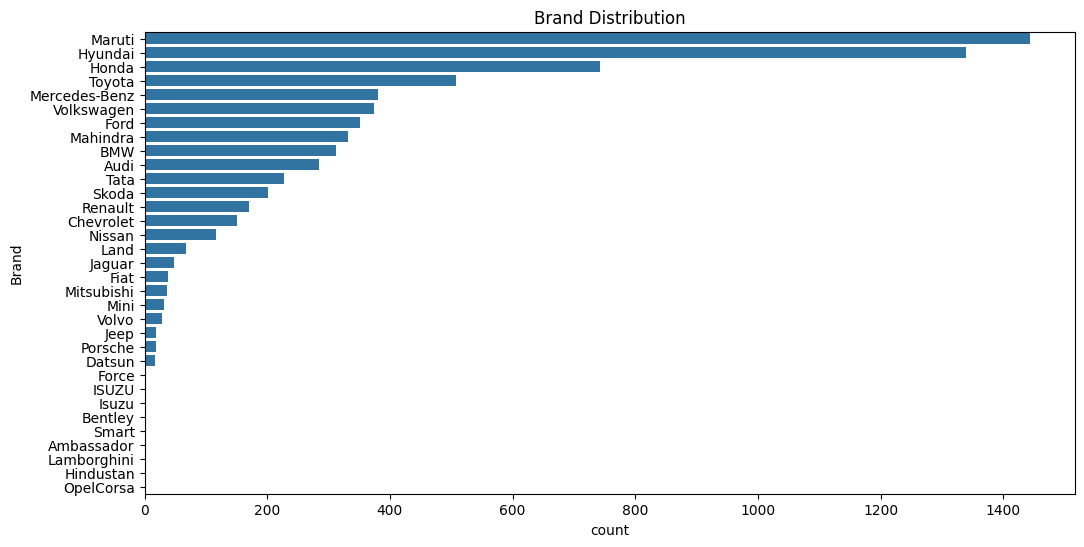

In [22]:
plt.figure(figsize=(12,6))

sns.countplot(y="Brand",data=df,order=df["Brand"].value_counts().index)

plt.title("Brand Distribution")
plt.show()

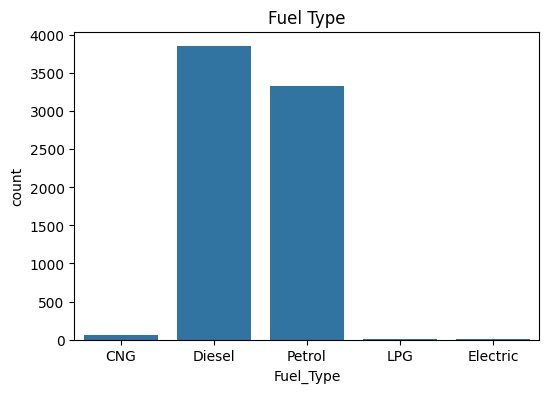

In [23]:
plt.figure(figsize=(6,4))

sns.countplot(
    x="Fuel_Type",
    data=df
)

plt.title("Fuel Type")
plt.show()

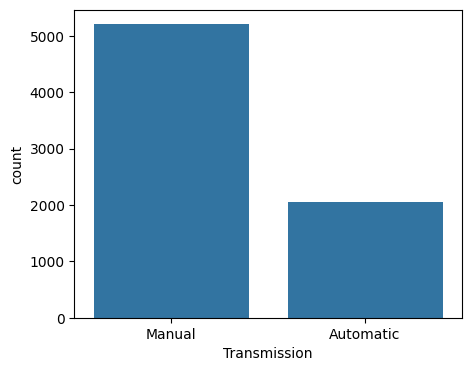

In [24]:
plt.figure(figsize=(5,4))

sns.countplot(x="Transmission",data=df)

plt.show()

In [25]:
encoder = LabelEncoder()

for col in cat_cols:
    df[col]=encoder.fit_transform(df[col])

In [26]:
X=df.drop("Price",axis=1)
y=df["Price"]

scaler = StandardScaler()
X_scaled=scaler.fit_transform(X)

In [27]:
selector=SelectKBest(score_func=mutual_info_regression,k=10)
X_selected=selector.fit_transform(X_scaled,y)

selected=X.columns[selector.get_support()]

print("\nTop Selected Features")
print(selected)


Top Selected Features
Index(['Name', 'Year', 'Transmission', 'Mileage', 'Engine', 'Power', 'Brand',
       'Car_Age', 'Price_per_KM', 'Power_per_Engine'],
      dtype='object')


In [28]:
scores=pd.DataFrame({"Feature":X.columns,"Score":selector.scores_})
print(scores.sort_values(
    by="Score",
    ascending=False)
     )

              Feature     Score
14       Price_per_KM  0.704924
0                Name  0.686991
9               Power  0.652647
15   Power_per_Engine  0.551869
8              Engine  0.530591
7             Mileage  0.379978
12              Brand  0.360734
13            Car_Age  0.235700
2                Year  0.223921
5        Transmission  0.199976
1            Location  0.158703
11          New_Price  0.133479
4           Fuel_Type  0.091528
10              Seats  0.073257
3   Kilometers_Driven  0.058364
6          Owner_Type  0.027583


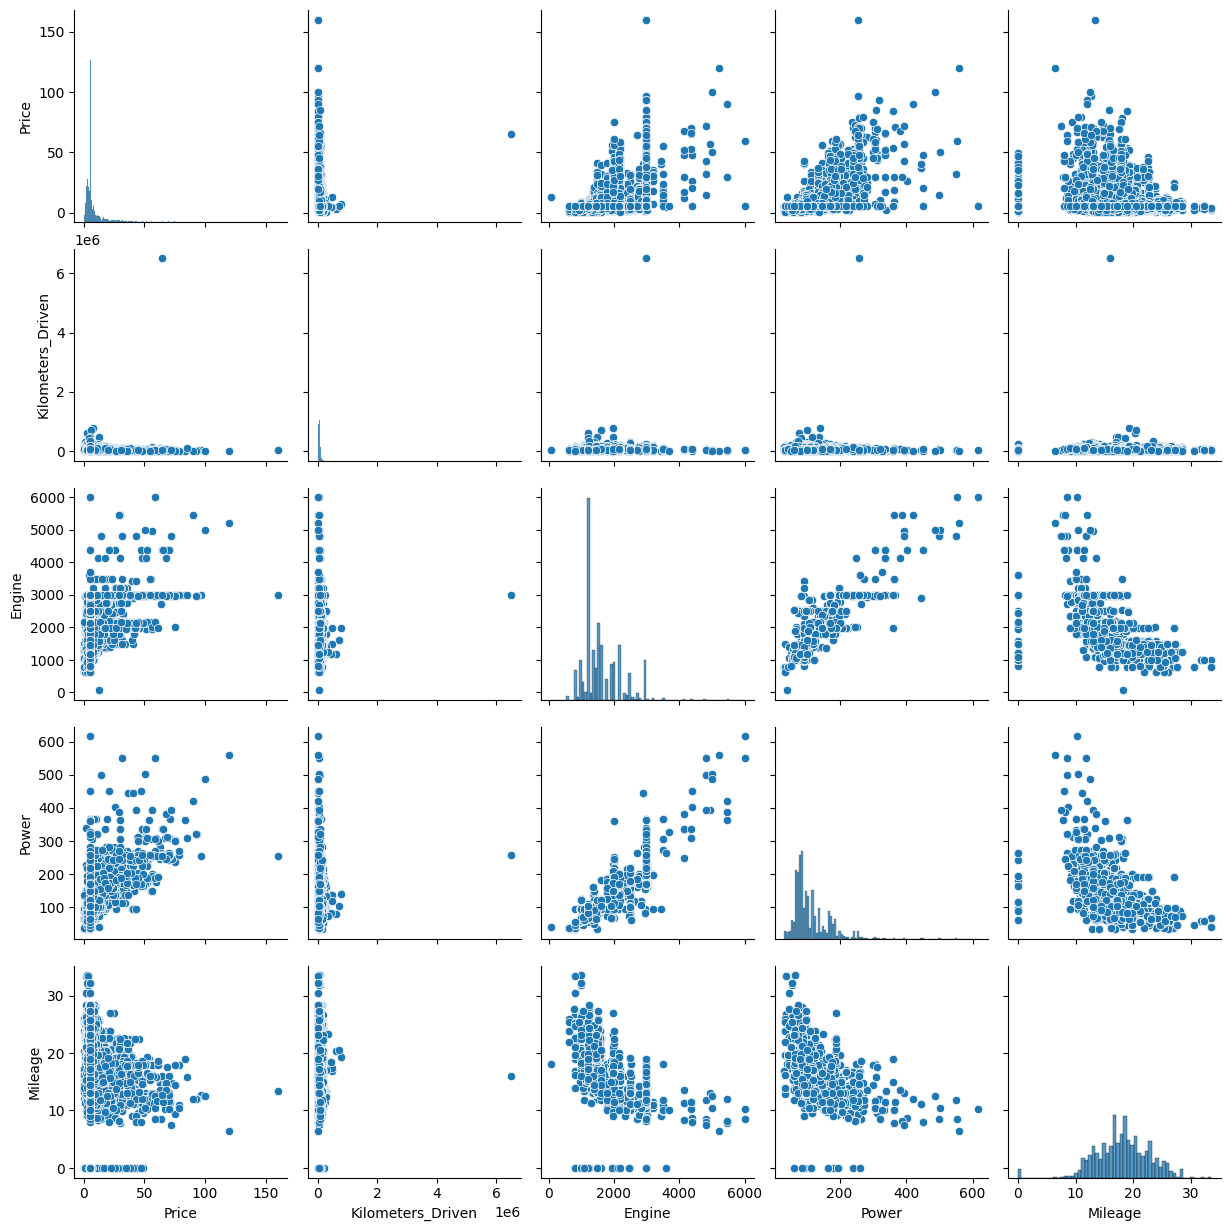

In [29]:
sns.pairplot(
    df[
        [
            "Price",
            "Kilometers_Driven",
            "Engine",
            "Power",
            "Mileage"
        ]
        ]
)

plt.show()